In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def Z(rho):
    pols = [
        np.ones_like(rho),  # 1st polynomial is constant
        np.sqrt(3) * (2 * rho**2 - 1),  # 2nd polynomial
        np.sqrt(5) * (6 * rho**4 - 6 * rho**2 + 1)  # 3rd polynomial
    ]
    return np.column_stack(pols)

In [3]:
def create_initial_coeff(rmax,R):
    return rmax**2/2/R*np.array([0.5,1/(2*np.sqrt(3)),0])

In [4]:
def generate_optic(a_n, zernpol):
    return np.dot(zernpol,a_n)

In [5]:
def create_starting_optic(r, R, k=-1):
    z = r * r / (R + np.sqrt(R * R - (k + 1) * r * r))
    return z

[5.62500000e-05 3.24759526e-05 0.00000000e+00]


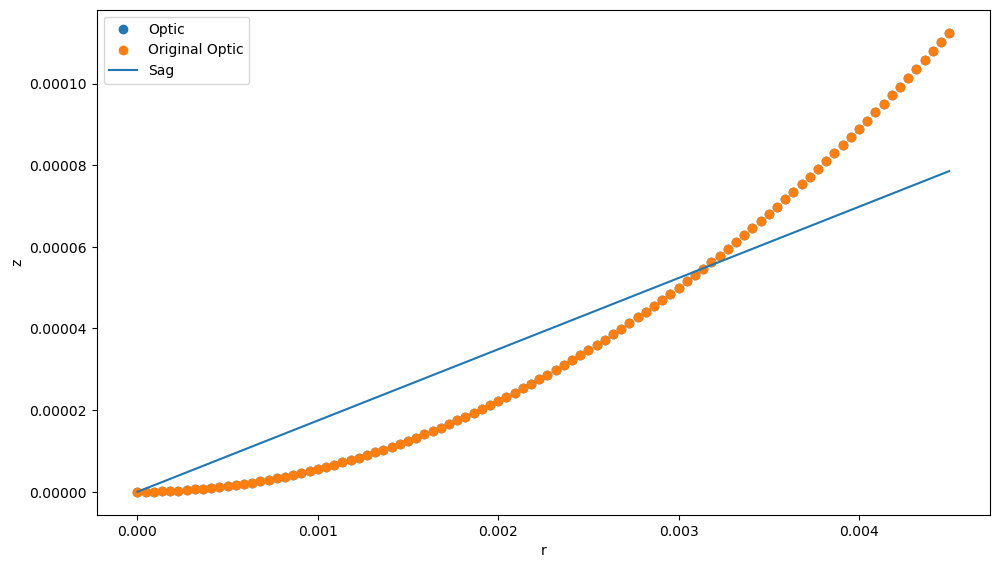

1.519596959708916e-19


In [6]:
w0=0.0009
r=np.linspace(0,5*w0,100)
plt.figure(figsize=(11.52, 6.56), dpi=100)

rho=r/max(r)
zernpol=Z(rho)
R=0.045*2
a_n=create_initial_coeff(5*w0,R)
optic=generate_optic(a_n,zernpol)
og_optic=create_starting_optic(r,R)
print(a_n)
plt.scatter(r,optic,label='Optic')
plt.scatter(r,og_optic,label='Original Optic')
sag=r*np.tan(1*np.pi/180)
plt.plot(r,sag,label='Sag')
plt.xlabel('r')
plt.ylabel('z')
# plt.plot(r,zernpol@a_n)
plt.legend()
plt.show()
print(np.sum((optic-og_optic)))

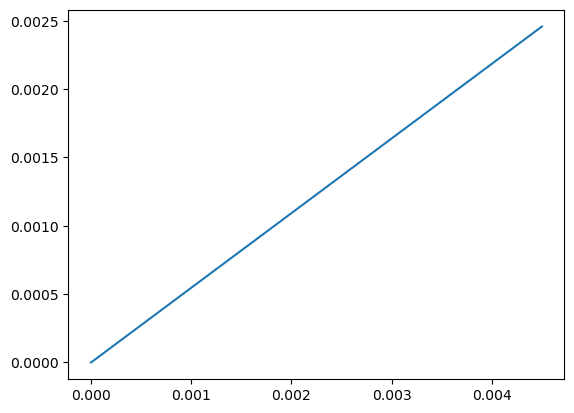

In [7]:
sag=r*np.tan(0.5)

plt.plot(r,sag,label='Sag')
plt.show()